# Walmart Weekly Sales Analysis

Exploratory data analysis of weekly sales across 45 Walmart stores: store performance, holiday effects, seasonality, and external factors.

# 1. Introduction

### 1.1. Objective
Understand what drives Walmart's weekly sales and turn the patterns into practical business insights.

### 1.2. Dataset
One row = one store in one week.

| Column | Description |
|---|---|
| `Store` | Store ID (1-45). An identifier, not a quantity |
| `Date` | Week date (dd-mm-yyyy) |
| `Weekly_Sales` | Total sales of the store that week |
| `Holiday_Flag` | 1 if the week contains a flagged holiday, otherwise 0 |
| `Temperature` | Temperature on the day of sale (values suggest Fahrenheit) |
| `Fuel_Price` | Fuel price in the store's region |
| `CPI` | Consumer Price Index |
| `Unemployment` | Unemployment rate in the store's region |

**Period:** weekly data from 2010-02-05 to 2012-10-26 (143 weeks per store).

**Data source:** Walmart Dataset (Kaggle), store-level weekly sales for 45 stores. Dataset page: https://www.kaggle.com/datasets/yasserh/walmart-dataset.

### 1.3. Business questions
1. What does the distribution of weekly sales look like?
2. Which stores sell the most and the least, and how large is the gap?
3. Are holiday weeks stronger than regular weeks?
4. How do sales change over time and across months?
5. Do temperature, fuel price, CPI, or unemployment relate to sales?
6. Does the holiday effect differ by store and by holiday?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from matplotlib.ticker import FuncFormatter
from scipy import stats

sns.set_theme(style='whitegrid')
pd.options.display.float_format = '{:,.2f}'.format   # no scientific notation, thousands separator

# axis label formatter: 1,500,000 -> 1.5M
millions = FuncFormatter(lambda x, pos: f'{x/1e6:.1f}M')

# 2. Data Loading and Cleaning

### 2.1. Inspect Data

In [2]:
df = pd.read_csv('Walmart.csv')
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,"1,643,690.90",0,42.31,2.57,211.10,8.11
1,1,12-02-2010,"1,641,957.44",1,38.51,2.55,211.24,8.11
2,1,19-02-2010,"1,611,968.17",0,39.93,2.51,211.29,8.11
3,1,26-02-2010,"1,409,727.59",0,46.63,2.56,211.32,8.11
4,1,05-03-2010,"1,554,806.68",0,46.50,2.62,211.35,8.11


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   str    
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), str(1)
memory usage: 465.2 KB


In [4]:
df.shape

(6435, 8)

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Store,"6,435.00",23.00,12.99,1.00,12.00,23.00,34.00,45.00
Weekly_Sales,"6,435.00","1,046,964.88","564,366.62","209,986.25","553,350.10","960,746.04","1,420,158.66","3,818,686.45"
Holiday_Flag,"6,435.00",0.07,0.26,0.00,0.00,0.00,0.00,1.00
Temperature,"6,435.00",60.66,18.44,-2.06,47.46,62.67,74.94,100.14
Fuel_Price,"6,435.00",3.36,0.46,2.47,2.93,3.44,3.73,4.47
CPI,"6,435.00",171.58,39.36,126.06,131.74,182.62,212.74,227.23
Unemployment,"6,435.00",8.00,1.88,3.88,6.89,7.87,8.62,14.31


### 2.2. Data Cleaning

In [6]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values per column:
Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64

Number of duplicate rows: 0


In [7]:
# Date was read as text (dd-mm-yyyy) -> convert to datetime
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True, errors='coerce')
print("Unparseable dates:", df['Date'].isna().sum())   # should be 0

df['Store'] = df['Store'].astype('category')   # store ID, not a quantity
# Holiday_Flag stays 0/1 (numeric) so it can be used in the correlation analysis

df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df = df.sort_values(['Store', 'Date']).reset_index(drop=True)

print("Date range:", df['Date'].min().date(), "to", df['Date'].max().date())
print("Weeks per store:", df.groupby('Store', observed=True)['Date'].count().unique())

Unparseable dates: 0
Date range: 2010-02-05 to 2012-10-26
Weeks per store: [143]


### 2.3. Feature Creation: store-relative sales
Stores differ hugely in size, so raw sales mix up "which store" with "which week".
`Sales_vs_Store_Avg` divides each week's sales by that store's own average, so **1.0 = a typical week for that store**, 1.2 = 20% above its usual level.

In [8]:
df['Sales_vs_Store_Avg'] = df['Weekly_Sales'] / df.groupby('Store', observed=True)['Weekly_Sales'].transform('mean')
df[['Store', 'Date', 'Weekly_Sales', 'Sales_vs_Store_Avg']].head()

,Store,Date,Weekly_Sales,Sales_vs_Store_Avg
0,1,2010-02-05,"1,643,690.90",1.06
1,1,2010-02-12,"1,641,957.44",1.06
2,1,2010-02-19,"1,611,968.17",1.04
3,1,2010-02-26,"1,409,727.59",0.91
4,1,2010-03-05,"1,554,806.68",1.00


# 3. Exploratory Data Analysis (EDA)

### 3.1. What does the distribution of weekly sales look like?

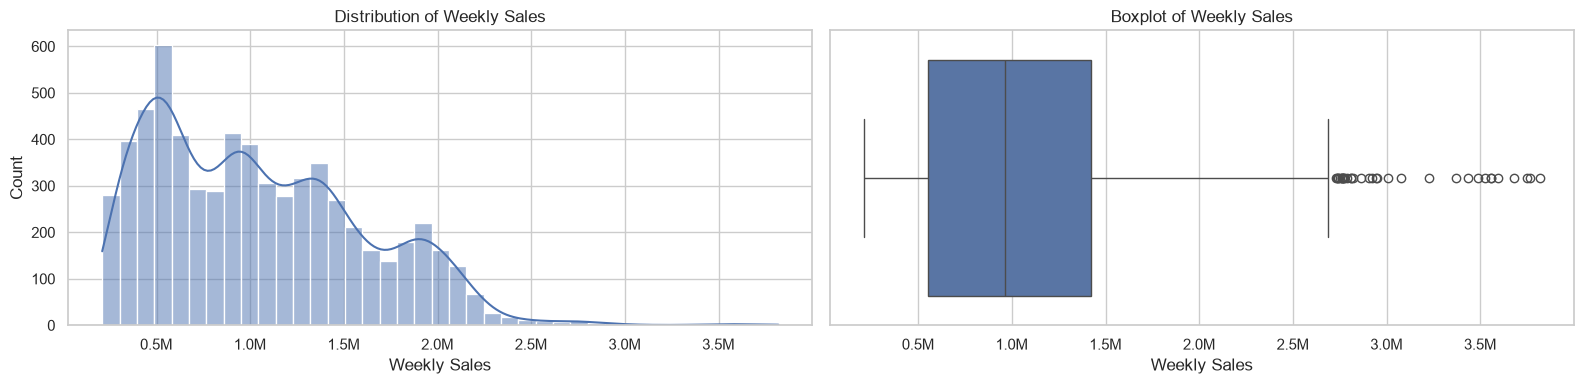

count       6,435.00
mean    1,046,965.00
std       564,367.00
min       209,986.00
25%       553,350.00
50%       960,746.00
75%     1,420,159.00
max     3,818,686.00
Name: Weekly_Sales, dtype: float64
Skewness: 0.668


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4))

sns.histplot(df['Weekly_Sales'], kde=True, ax=ax[0])
ax[0].set_title('Distribution of Weekly Sales')
ax[0].set_xlabel('Weekly Sales')
ax[0].xaxis.set_major_formatter(millions)

sns.boxplot(x=df['Weekly_Sales'], ax=ax[1])
ax[1].set_title('Boxplot of Weekly Sales')
ax[1].set_xlabel('Weekly Sales')
ax[1].xaxis.set_major_formatter(millions)

plt.tight_layout()
plt.show()

print(df['Weekly_Sales'].describe().round(0))
print('Skewness:', round(df['Weekly_Sales'].skew(), 3))

**Distribution of Weekly Sales**
Weekly sales are moderately right-skewed (skewness 0.668). The mean (about 1.05M) is higher than the median (about 0.96M), and sales range from about 0.21M to 3.82M. The multiple peaks and the points in the upper tail point to differences in store size rather than errors, which the next section checks.

### 3.2. Which stores have the highest and lowest average weekly sales?

In [10]:
store_average = df.groupby('Store', observed=True)['Weekly_Sales'].mean().sort_values(ascending=False)

print('Top 3 stores:')
print(store_average.head(3).map('{:,.0f}'.format))
print('\nBottom 3 stores:')
print(store_average.tail(3).map('{:,.0f}'.format))
print(f'\nLargest vs smallest store average: {store_average.max() / store_average.min():.1f}x')

Top 3 stores:
Store
20    2,107,677
4     2,094,713
14    2,020,978
Name: Weekly_Sales, dtype: str

Bottom 3 stores:
Store
5     318,012
44    302,749
33    259,862
Name: Weekly_Sales, dtype: str

Largest vs smallest store average: 8.1x


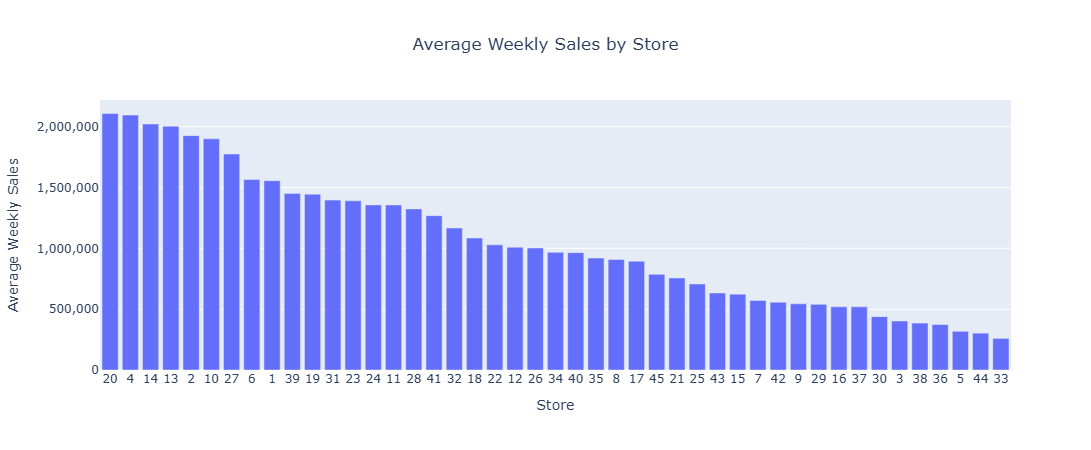

In [11]:
plot_df = store_average.reset_index()
plot_df.columns = ['Store', 'Avg_Weekly_Sales']
plot_df['Store'] = plot_df['Store'].astype(str)   # treat store IDs as labels

fig = px.bar(plot_df, x='Store', y='Avg_Weekly_Sales',
             title='Average Weekly Sales by Store',
             labels={'Avg_Weekly_Sales': 'Average Weekly Sales'})
fig.update_layout(width=1000, height=450, title_x=0.5)
fig.update_xaxes(categoryorder='array', categoryarray=plot_df['Store'])   # keep sorted order
fig.update_yaxes(tickformat=',.0f')
fig.show()

**Sales Performance Varies Strongly Across Stores**
Store 20 has the highest average weekly sales (about 2.11M) and Store 33 the lowest (about 0.26M), a gap of roughly **8.1x**. Six stores (20, 4, 14, 13, 2, 10) average about 1.9M to 2.1M per week, while the smallest stores (33, 44, 5, 36, 38) average below 0.4M. Store identity is therefore the biggest source of variation in weekly sales, and later comparisons should account for it.

### 3.3. Are holiday weeks stronger than regular weeks?

In [12]:
normal = df.loc[df['Holiday_Flag'] == 0, 'Weekly_Sales']
holiday = df.loc[df['Holiday_Flag'] == 1, 'Weekly_Sales']

difference = holiday.mean() - normal.mean()
percentage = difference / normal.mean() * 100

print(f'Holiday weeks share of data : {len(holiday) / len(df):.1%}')
print(f'Normal weeks  (mean) : {normal.mean():,.0f}')
print(f'Holiday weeks (mean) : {holiday.mean():,.0f}')
print(f'Difference           : {difference:,.0f}')
print(f'Percentage           : {percentage:.2f}%')
print(f'Median normal vs holiday: {normal.median():,.0f} vs {holiday.median():,.0f}')

# Is the difference statistically meaningful? Compare store-relative sales (removes store size effect)
h_rel = df.loc[df['Holiday_Flag'] == 1, 'Sales_vs_Store_Avg']
n_rel = df.loc[df['Holiday_Flag'] == 0, 'Sales_vs_Store_Avg']
u, p = stats.mannwhitneyu(h_rel, n_rel, alternative='two-sided')
print(f'\nStore-relative sales: holiday {h_rel.mean():.3f} vs normal {n_rel.mean():.3f} (1.0 = store average)')
print(f'Mann-Whitney U test p-value: {p:.4g}')

Holiday weeks share of data : 7.0%
Normal weeks  (mean) : 1,041,256
Holiday weeks (mean) : 1,122,888
Difference           : 81,632
Percentage           : 7.84%
Median normal vs holiday: 956,211 vs 1,018,538

Store-relative sales: holiday 1.068 vs normal 0.995 (1.0 = store average)
Mann-Whitney U test p-value: 8.158e-12


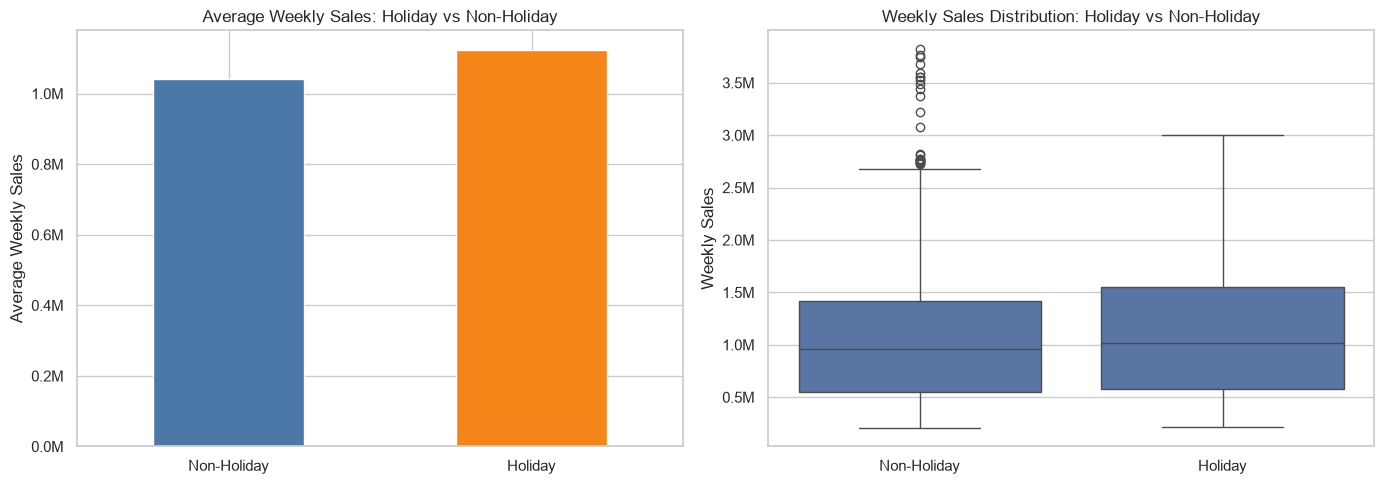

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

avg_by_flag = df.groupby('Holiday_Flag')['Weekly_Sales'].mean()
avg_by_flag.plot(kind='bar', ax=ax[0], color=['#4C78A8', '#F58518'])
ax[0].set_title('Average Weekly Sales: Holiday vs Non-Holiday')
ax[0].set_xlabel('')
ax[0].set_ylabel('Average Weekly Sales')
ax[0].set_xticklabels(['Non-Holiday', 'Holiday'], rotation=0)
ax[0].yaxis.set_major_formatter(millions)

sns.boxplot(data=df, x='Holiday_Flag', y='Weekly_Sales', ax=ax[1])
ax[1].set_title('Weekly Sales Distribution: Holiday vs Non-Holiday')
ax[1].set_xlabel('')
ax[1].set_ylabel('Weekly Sales')
ax[1].set_xticks([0, 1])
ax[1].set_xticklabels(['Non-Holiday', 'Holiday'])
ax[1].yaxis.set_major_formatter(millions)

plt.tight_layout()
plt.show()

**Holiday vs Non-Holiday Weeks**
Average weekly sales in flagged holiday weeks (about 1.12M) were roughly **7.84% higher** than in regular weeks (about 1.04M). The medians are higher in holiday weeks too, but the two boxes overlap heavily, so holiday weeks lift sales only modestly on average. The Mann-Whitney test on store-relative sales (printed above) checks whether the gap is larger than random variation. Note that `Holiday_Flag` marks only specific weeks, so this comparison does not capture every seasonal peak (see 3.7).

### 3.4. How do sales change over time?

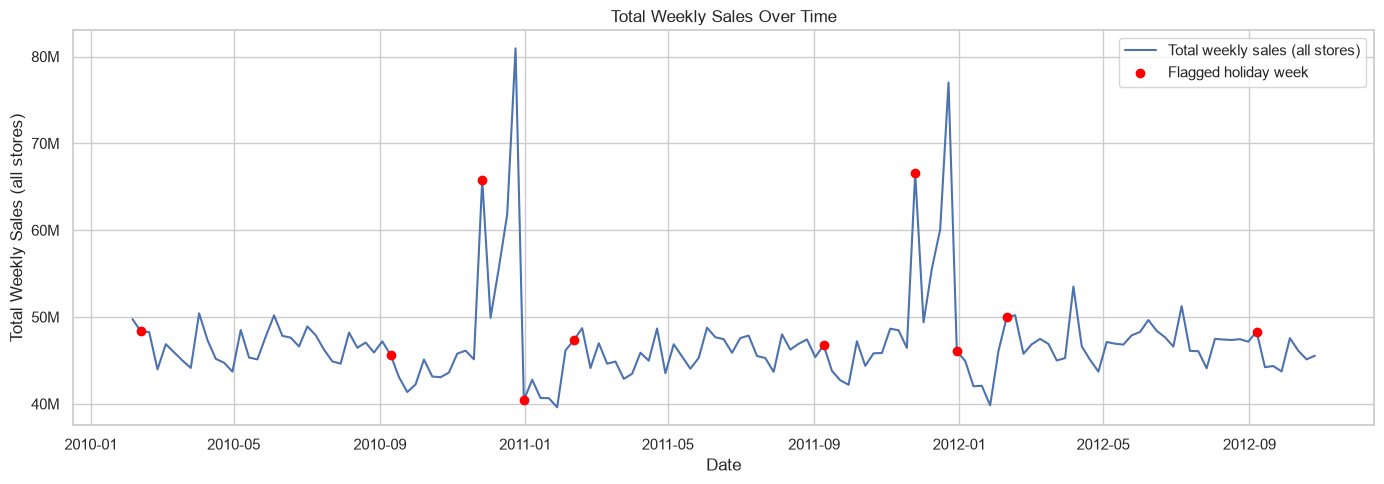

In [14]:
total = df.groupby('Date')['Weekly_Sales'].sum()
holiday_weeks = pd.DatetimeIndex(df.loc[df['Holiday_Flag'] == 1, 'Date'].unique())

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(total.index, total.values, label='Total weekly sales (all stores)')
ax.scatter(holiday_weeks, total.loc[holiday_weeks], color='red', zorder=3, label='Flagged holiday week')
ax.set_title('Total Weekly Sales Over Time')
ax.set_xlabel('Date')
ax.set_ylabel('Total Weekly Sales (all stores)')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x/1e6:.0f}M'))
ax.legend()
plt.tight_layout()
plt.show()

**Sales Trend Over Time**
Total weekly sales fluctuate throughout the observation period with no sustained upward or downward trend. Several pronounced spikes occur near the end of each year and then fall back, which suggests seasonal shopping patterns rather than lasting growth. The red dots show which weeks carry the holiday flag; section 3.7 checks whether the biggest spikes are actually flagged.

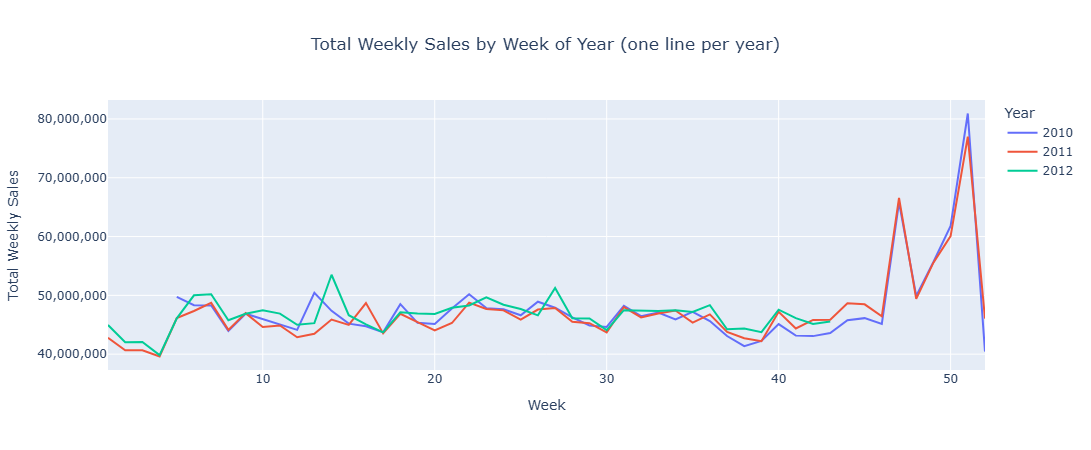

      Avg_total_per_week  Weeks_in_data
Year                                   
2010       47,685,127.51             48
2011       47,080,769.37             52
2012       46,514,717.66             43


In [15]:
total_df = total.reset_index()
total_df.columns = ['Date', 'Total_Sales']
total_df['Year'] = total_df['Date'].dt.year.astype(str)
total_df['Week'] = total_df['Date'].dt.isocalendar().week.astype(int)

fig = px.line(total_df, x='Week', y='Total_Sales', color='Year',
              title='Total Weekly Sales by Week of Year (one line per year)',
              labels={'Total_Sales': 'Total Weekly Sales'})
fig.update_layout(width=1000, height=450, title_x=0.5)
fig.update_yaxes(tickformat=',.0f')
fig.show()

# 2010 and 2012 are partial years, so compare weekly averages instead of yearly totals
print(total_df.groupby('Year')['Total_Sales'].agg(['mean', 'count']).rename(
    columns={'mean': 'Avg_total_per_week', 'count': 'Weeks_in_data'}))

**Year-over-Year Comparison**
*The weekly sales pattern repeats almost identically in 2010-2012: low at the start of the year, a gradual rise, then a sharp jump near-end(visible in 2010 and 2011 ; the 2012 data stops around week 143). Average total sales per week were about 47.7M, 47.1M and 46.5M, roughly flat with a slight decline of about 1% per year. Because 2010 starts in February and 2012 ends in October, these averages are not fully comparable. Seasonality is much stronger than any year change.*

Years in data per month (months are not equally represented):
Month
1     2
2     3
3     3
4     3
5     3
6     3
7     3
8     3
9     3
10    3
11    2
12    2


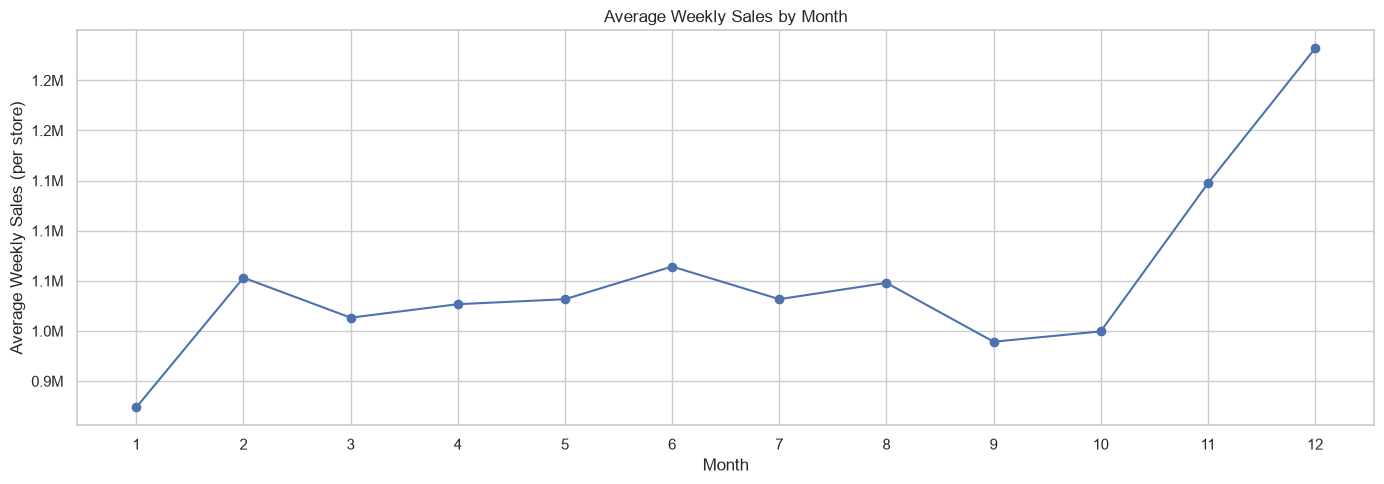

Month
1       923,885
9       989,335
10      999,632
3     1,013,309
4     1,026,762
5     1,031,714
7     1,031,748
8     1,048,017
2     1,053,200
6     1,064,325
11    1,147,266
12    1,281,864
Name: Weekly_Sales, dtype: str


In [16]:
print('Years in data per month (months are not equally represented):')
print(df.groupby('Month')['Year'].nunique().to_string())

monthly_sales = df.groupby('Month')['Weekly_Sales'].mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(monthly_sales.index, monthly_sales.values, marker='o')
ax.set_xticks(range(1, 13))
ax.set_title('Average Weekly Sales by Month')
ax.set_xlabel('Month')
ax.set_ylabel('Average Weekly Sales (per store)')
ax.yaxis.set_major_formatter(millions)
plt.tight_layout()
plt.show()

print(monthly_sales.sort_values().map('{:,.0f}'.format))

**Seasonality by Month**
Averages (not sums) are used because the months are not equally represented in the data, and sums would make under-represented months look weak. December is the strongest month (about 1.28M per store-week), followed by November (about 1.15M). January is the weakest (about 0.92M), so December runs roughly **39% above January**. The other months stay between about 0.99M and 1.06M, so the year-end peak is the one clear seasonal effect.

### 3.5. Is there a relationship between temperature, fuel price, CPI, unemployment, and sales?

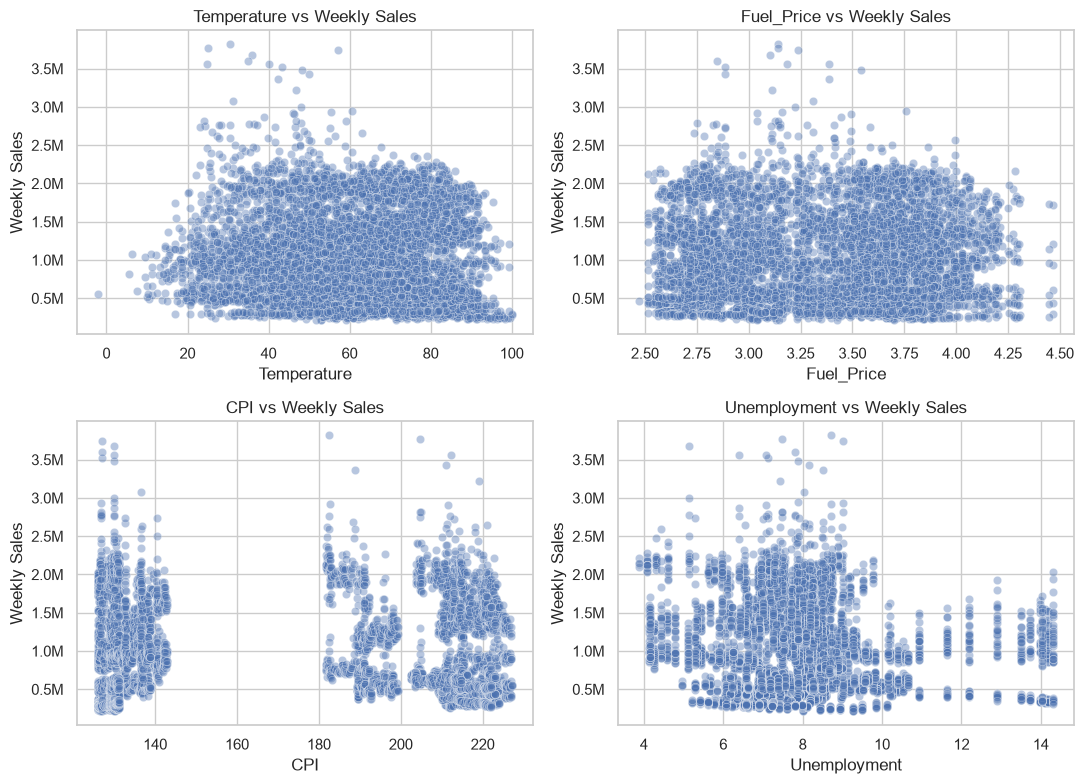

In [17]:
features = ['Temperature', 'Fuel_Price', 'CPI', 'Unemployment']

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for col, ax in zip(features, axes.flatten()):
    sns.scatterplot(data=df, x=col, y='Weekly_Sales', ax=ax, alpha=0.4)
    ax.set_title(f'{col} vs Weekly Sales')
    ax.set_xlabel(col)
    ax.set_ylabel('Weekly Sales')
    ax.yaxis.set_major_formatter(millions)
plt.tight_layout()
plt.show()

**External Factors and Weekly Sales (raw sales)**
The scatterplots show no clear linear relationship between weekly sales and `Temperature`, `Fuel_Price`, `CPI`, or `Unemployment`. However, raw sales mix big and small stores, and `CPI` and `Unemployment` differ by region, so the next check removes the store-size effect.

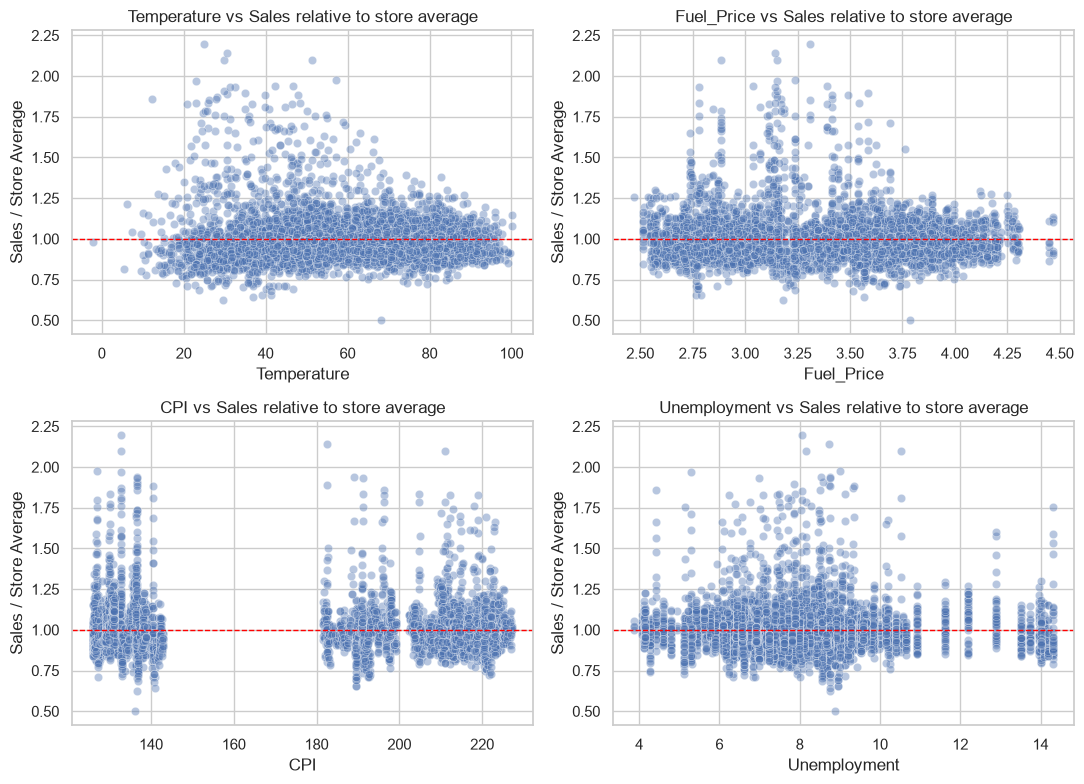

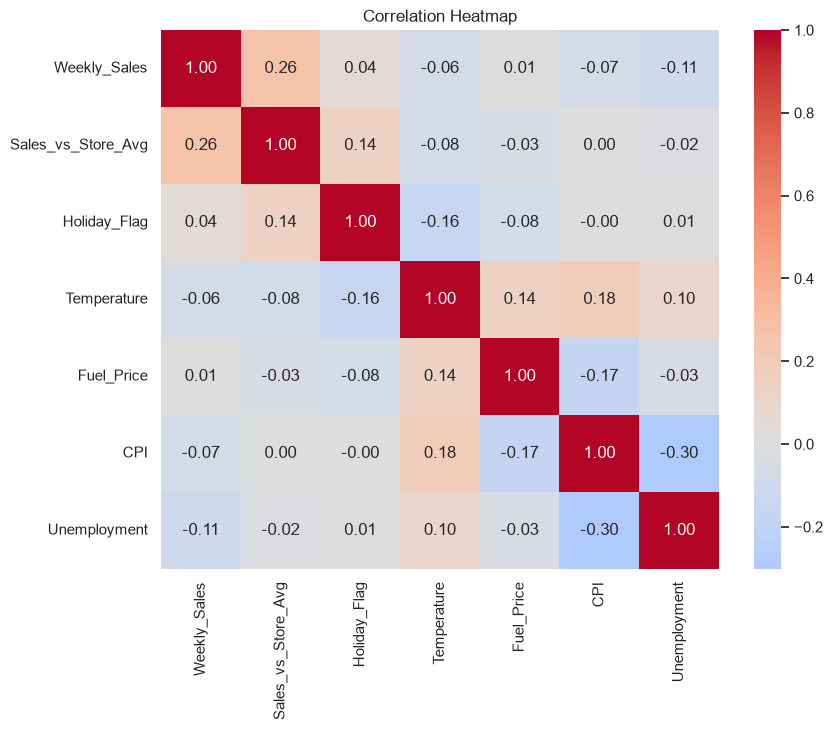

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for col, ax in zip(features, axes.flatten()):
    sns.scatterplot(data=df, x=col, y='Sales_vs_Store_Avg', ax=ax, alpha=0.4)
    ax.axhline(1, color='red', linestyle='--', linewidth=1)
    ax.set_title(f'{col} vs Sales relative to store average')
    ax.set_xlabel(col)
    ax.set_ylabel('Sales / Store Average')
plt.tight_layout()
plt.show()

corr_cols = ['Weekly_Sales', 'Sales_vs_Store_Avg', 'Holiday_Flag'] + features
plt.figure(figsize=(9, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.show()

### 3.6. Does the holiday effect differ by store?

In [19]:
holiday_by_store = df.groupby(['Store', 'Holiday_Flag'], observed=True)['Weekly_Sales'].mean().unstack()
holiday_by_store.columns = ['Non_Holiday', 'Holiday']
holiday_by_store['Pct_Change'] = ((holiday_by_store['Holiday'] - holiday_by_store['Non_Holiday'])
                                  / holiday_by_store['Non_Holiday'] * 100).round(1)

print('Stores with higher sales in holiday weeks:',
      (holiday_by_store['Pct_Change'] > 0).sum(), 'of', len(holiday_by_store))
print('\nLargest holiday increases:')
print(holiday_by_store['Pct_Change'].sort_values(ascending=False).head(3).to_string())
print('\nLowest holiday change:')
print(holiday_by_store['Pct_Change'].sort_values().head(5).to_string())

Stores with higher sales in holiday weeks: 40 of 45

Largest holiday increases:
Store
7    19.40
35   18.30
15   14.50

Lowest holiday change:
Store
44   -2.40
37   -2.40
36   -1.70
38   -1.20
30   -0.40


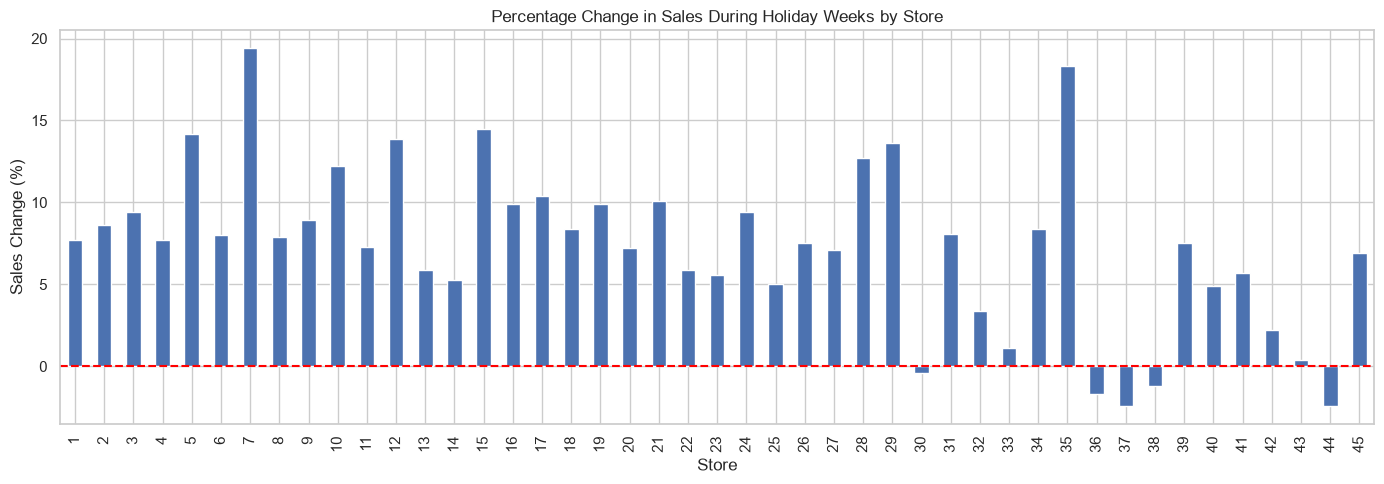

In [20]:
fig, ax = plt.subplots(figsize=(14, 5))
holiday_by_store['Pct_Change'].plot(kind='bar', ax=ax)
ax.axhline(0, color='red', linestyle='--')
ax.set_title('Percentage Change in Sales During Holiday Weeks by Store')
ax.set_xlabel('Store')
ax.set_ylabel('Sales Change (%)')
plt.tight_layout()
plt.show()

**Business Insight: Holiday Effect Differs by Store**
Most stores (about 40 of 45) sold more in holiday weeks, typically around 5% to 15% more. Stores 7 and 35 show the largest gains (about 18% to 19%). Five stores (30, 36, 37, 38, 44) show a slightly negative change of about -0.4% to -2.4%, and all five are among the eight lowest-selling stores. Holiday weeks therefore do not lift sales equally everywhere, and a single chain-wide holiday assumption would over- or under-estimate individual stores.

### 3.7. Which holidays matter, and are the biggest weeks flagged?

Flagged weeks outside the four expected months: 0
Sales change vs store average, by holiday (%):
Holiday
Thanksgiving   37.60
Super Bowl      2.90
Labor Day       0.00
25 December    -7.90


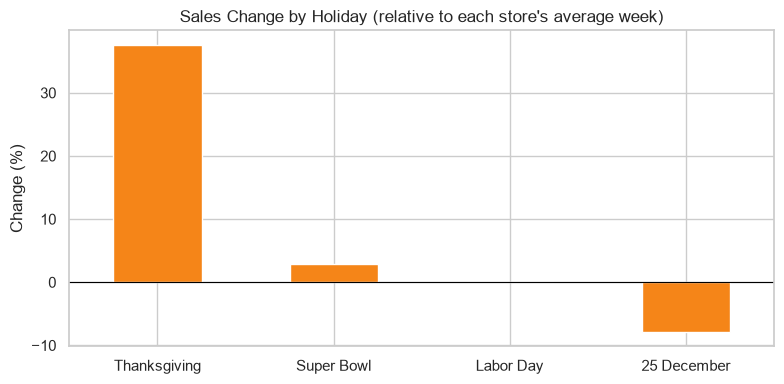

In [23]:
# Flagged weeks fall in Feb (Super Bowl), Sep (Labor Day), Nov (Thanksgiving), Dec (Christmas)
holiday_names = {2: 'Super Bowl', 9: 'Labor Day', 11: 'Thanksgiving', 12: '25 December'}
hol = df[df['Holiday_Flag'] == 1].copy()
hol['Holiday'] = hol['Month'].map(holiday_names)
print('Flagged weeks outside the four expected months:', hol['Holiday'].isna().sum())   # should be 0

by_holiday = hol.groupby('Holiday')['Sales_vs_Store_Avg'].mean().sort_values(ascending=False)
by_holiday_pct = ((by_holiday - 1) * 100).round(1)
print('Sales change vs store average, by holiday (%):')
print(by_holiday_pct.to_string())

fig, ax = plt.subplots(figsize=(8, 4))
by_holiday_pct.plot(kind='bar', ax=ax, color='#F58518')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Sales Change by Holiday (relative to each store\'s average week)')
ax.set_xlabel('')
ax.set_ylabel('Change (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [22]:
top_weeks = total.sort_values(ascending=False).head(10).to_frame('Total_Weekly_Sales')
top_weeks['Holiday_Flag'] = df.groupby('Date')['Holiday_Flag'].max().loc[top_weeks.index]
print('Top 10 weeks by total sales:')
display(top_weeks.style.format({'Total_Weekly_Sales': '{:,.0f}'}))
print('Flagged as holiday:', int(top_weeks['Holiday_Flag'].sum()), 'of 10')

Top 10 weeks by total sales:


,Total_Weekly_Sales,Holiday_Flag
Date,,
2010-12-24 00:00:00,"80,931,416",0
2011-12-23 00:00:00,"76,998,241",0
2011-11-25 00:00:00,"66,593,605",1
2010-11-26 00:00:00,"65,821,003",1
2010-12-17 00:00:00,"61,820,800",0
2011-12-16 00:00:00,"60,085,696",0
2010-12-10 00:00:00,"55,666,770",0
2011-12-09 00:00:00,"55,561,148",0
2012-04-06 00:00:00,"53,502,316",0


Flagged as holiday: 2 of 10


**Which Holidays Matter**
*The biggest holiday lift is Thanksgiving and the weakest is 25 December (negative). From the top 10 biggest sales, only 2 (3th and 4th) sales weeks carry `Holiday_Flag = 1`.*

# 4. Conclusions and Recommendations

### 4.1. Key findings
1. **Store identity matters most.** The largest store averages about 8.1x the smallest (about 2.11M vs 0.26M per week).
2. **Sales are moderately right-skewed** (skewness 0.668), with a typical store-week around 1.0M.
3. **Holiday weeks lift sales modestly:** about 7.84% higher on average, but the effect ranges from about +19% at some stores to slightly negative at five small stores.
4. **Seasonality is concentrated at year end.** December averages about 1.28M per store-week, roughly 39% above January, with November also elevated.
5. **External factors** (temperature, fuel price, CPI, unemployment) show no clear linear relationship with raw sales in the scatterplots; the store-relative check in 3.5 tests this more carefully.

### 4.2. Recommendations
- **Plan inventory and staffing around November and December**, the clearest seasonal peak.
- **Set store-specific targets** instead of one chain-wide holiday uplift, since store size and holiday response differ widely.
- **Review the small stores with flat or negative holiday weeks** (30, 36, 37, 38, 44) to understand why holidays do not lift them.
- **Use `Month`/`Week` together with `Holiday_Flag`** when forecasting, because the flag marks only specific weeks (see 3.7).

### 4.3. Limitations
- Only about three years of weekly data, so each season appears just two or three times.
- Total sales only: no product, department, price, or promotion data.
- `Holiday_Flag` covers specific weeks only and mixes four different holidays.
- `CPI`, `Unemployment`, and `Fuel_Price` are regional and change slowly, so they carry little week-to-week information.
- The analysis is descriptive: associations here are not proof of cause and effect.

### 4.4. Next steps
Build a forecasting model (time-based train/test split, per-store lag features) and compare it with a simple "last week" baseline.